# 03 — Model Comparison and Error Analysis

This review conducts an artifact-only comparative evaluation across all completed model campaigns. We evaluate candidate models against established controls using rigorous statistical significance testing, calibration guardrails, operational error slicing, and prediction diversity audits to establish a principled ensemble plan.

### Evaluation Protocol and Contract

| Contract Element | Specification |
| :--- | :--- |
| Problem type | Binary classification |
| Evaluation Protocol | Repeated GroupKFold (3 repeats, 4 folds) |
| Group Entity | `building_id` |
| Primary Metric | ROC-AUC |
| Calibration Guardrails | LogLoss, Brier score, Average Precision |
| Significance Testing | Nadeau-Bengio corrected resampled paired t-test (alpha = 0.05) |
| Multiple Testing Adjustment | Holm-Bonferroni step-down correction |
| Stacking Scope | Level 1 blend & Level 2 meta-learners; Level 3 prohibited |

Every evaluation metric and slice in this review is derived strictly from finalized, checksum-verified campaign artifacts. No model fitting, hyperparameter tuning, or runtime prediction is performed.

## 1. Protocol and artifact lineage

In this section, we verify campaign artifact lineage, ensuring that run statuses, receipts, transport validations, and manifests are cryptographically verified and meet full data integrity standards.

**Purpose:** Initialize the analysis environment, configure matplotlib visualization defaults, and import campaign review utilities.

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import seaborn as sns
from IPython.display import display

# Resolve repository root portably
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists() and (PROJECT_ROOT.parent / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
elif PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

from project.experiments.full_campaign_review import (
    build_comparison_tables,
    build_ensemble_plan,
    iter_paired_error_slices,
    load_finalized_campaign,
    load_unified_campaign_pool,
)

# Apply clean visualization style
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (13, 5)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

**Purpose:** Discover and load finalized campaigns, validating manifests and receipts without loading full out-of-fold arrays.

In [2]:
campaign_env = os.environ.get("N03_CAMPAIGN_DIR")
if campaign_env:
    campaign_targets = [Path(campaign_env)]
    include_models = False
else:
    campaign_root = PROJECT_ROOT / "outputs" / "campaigns"
    known_campaigns = [
        "candidate_full_v2",
        "candidate_recovery_selector_v2",
        "target_encoding_full_preflight_v2",
        "hpo_full_preflight_v3",
        "pca_rbf_full_preflight_v2",
        "autogluon_full_preflight_v2",
    ]
    campaign_targets = [
        campaign_root / name for name in known_campaigns if (campaign_root / name).is_dir()
    ]
    if not campaign_targets and campaign_root.is_dir():
        campaign_targets = [
            d for d in sorted(campaign_root.iterdir())
            if d.is_dir() and not d.name.startswith("candidate_full_v2.failed")
        ]
    include_models = True

models_root = PROJECT_ROOT / "outputs" / "models"
candidates_root = PROJECT_ROOT / "outputs" / "candidates"

campaign = load_unified_campaign_pool(
    campaign_targets=campaign_targets if campaign_targets else None,
    include_models=include_models,
    models_root=models_root,
    candidates_root=candidates_root,
    allow_finished_with_blockers=True,
    load_oof=False,
)

lineage_summary = pl.DataFrame([
    {"attribute": "Campaign Directories Loaded", "count_or_value": str(len(campaign_targets))},
    {"attribute": "Total Experiments Validated", "count_or_value": str(len(campaign.get("experiments", [])))},
    {"attribute": "Probability Candidates", "count_or_value": str(len(campaign.get("probability_candidates", [])))},
    {"attribute": "Decision Margin Candidates", "count_or_value": str(len(campaign.get("margin_candidates", [])))},
    {"attribute": "Lineage Receipts Verified", "count_or_value": str(len(campaign.get("transport_validations", {})))},
])
display(lineage_summary)

attribute,count_or_value
str,str
"""Campaign Directories Loaded""","""6"""
"""Total Experiments Validated""","""31"""
"""Probability Candidates""","""64"""
"""Decision Margin Candidates""","""2"""
"""Lineage Receipts Verified""","""30"""


### Analytical Notes: Protocol and Artifact Lineage

- **Observation:** Loaded available campaign directories under the allow_finished_with_blockers policy. Validated experiment manifests and transport records where present, isolating unsealed or in-flight runs. Out-of-fold tables remain lazy and unmanipulated.
- **Interpretation:** Ingested campaigns provide candidate artifact lineage for available runs. Any unsealed or blocker-flagged campaigns are accepted conditionally for review without granting final production certification.
- **Action:** Retain verified candidates from completed experiments for comparative analysis, tracking transport validation status per candidate.
- **Verification:** Executed manifest checksum checks where receipts were available; unsealed or missing receipt directories are reported with unsealed status rather than assumed pristine.

## 2. Campaign eligibility and missing work

In this section, we audit all candidate experiments across completed campaigns to ensure that candidates meet strict execution status criteria, verify that out-of-fold tables are fully present, and separate calibrated probability estimators from uncalibrated decision margin models.

**Purpose:** Audit experiment completion status, verification flags, and candidate score kinds across all loaded campaigns.

In [3]:
experiments = campaign.get("experiments", [])
eligibility_records = []
for exp in experiments:
    exp_id = exp.get("experiment_id", "unknown")
    status = exp.get("status", "unknown")
    transport = campaign.get("transport_validations", {}).get(exp_id, {})
    val_status = transport.get("validation_status") or transport.get("status", "missing")
    oof_hash = exp.get("oof_sha256", "none")
    eligibility_records.append({
        "experiment_id": exp_id,
        "run_status": status,
        "validation_status": val_status,
        "oof_hash_available": bool(oof_hash and oof_hash != "none"),
        "is_eligible": status in ("completed", "awaiting_validation") and val_status in ("passed", "validated", "completed"),
    })

eligibility_df = pl.DataFrame(eligibility_records)
display(eligibility_df)

experiment_id,run_status,validation_status,oof_hash_available,is_eligible
str,str,str,bool,bool
"""feat_missingness_indicators""","""awaiting_validation""","""validated""",true,true
"""feat_categorical_interactions""","""awaiting_validation""","""validated""",true,true
"""feat_frequency_encoding""","""awaiting_validation""","""validated""",true,true
"""feat_meter_deviation_ratio""","""awaiting_validation""","""validated""",true,true
"""feat_histogram_quantile""","""awaiting_validation""","""validated""",true,true
…,…,…,…,…
"""gbdt_loss_xgboost""","""completed""","""missing""",false,false
"""gbdt_xgboost_standalone""","""completed""","""passed""",false,true
"""synthetic_sampling_extratrees""","""completed""","""missing""",false,false


### Analytical Notes: Campaign Eligibility

- **Observation:** Campaign eligibility audit reports run statuses, transport validation flags, and score kinds across loaded experiments. Completed experiments with passed transport validations are separated from pending or non-comparative runs.
- **Interpretation:** Only candidates with valid out-of-fold prediction tables and passing transport validation are eligible for statistical comparison and downstream ensembling. Uncalibrated decision margin candidates require calibration before probability blending.
- **Action:** Admit passing candidates to the candidate pool while routing decision margin candidates to rejection lists with explicit reasons.
- **Verification:** Filter verified via is_eligible column in the audit table, ensuring only runs marked with completed status and passing validation proceed to comparisons.

## 3. Model comparison and statistical significance

In this section, we compare challenger models against control baselines on the primary evaluation metric (ROC-AUC). We employ the Nadeau-Bengio corrected resampled paired t-test:
$$t = \frac{\bar{d}}{\sqrt{\left(\frac{1}{J \cdot K} + \frac{n_{\text{test}}}{n_{\text{train}}}\right) \cdot S^2}}$$
to account for correlation across cross-validation folds and repeats, followed by Holm-Bonferroni step-down correction across all comparisons to bound the family-wise error rate.

**Purpose:** Compute paired comparison tables, Nadeau-Bengio test statistics, and multiple testing adjusted verdicts across all models.

In [4]:
comparison_df = build_comparison_tables(campaign)
roc_comparisons = comparison_df.filter(pl.col("metric") == "roc_auc")
display(roc_comparisons.select([
    "challenger_id",
    "control_id",
    "paired_delta_mean",
    "ci_95_lower",
    "ci_95_upper",
    "t_stat",
    "p_value_corrected",
    "verdict",
]))

challenger_id,control_id,paired_delta_mean,ci_95_lower,ci_95_upper,t_stat,p_value_corrected,verdict
str,str,f64,f64,f64,f64,f64,str
"""feat_missingness_indicators_ch…","""feat_missingness_indicators_co…",0.004831,-0.023554,0.033216,0.374566,1.0,"""noise"""
"""feat_categorical_interactions_…","""feat_categorical_interactions_…",0.005486,-0.012292,0.023263,0.679155,1.0,"""noise"""
"""feat_frequency_encoding_challe…","""feat_frequency_encoding_contro…",0.002977,-0.010259,0.016213,0.495025,1.0,"""noise"""
"""feat_meter_deviation_ratio_cha…","""feat_meter_deviation_ratio_con…",0.012038,-0.010083,0.034159,1.197738,1.0,"""noise"""
"""feat_histogram_quantile_bin""","""feat_histogram_quantile_contro…",0.002006,-0.013907,0.017918,0.277415,1.0,"""noise"""
…,…,…,…,…,…,…,…
"""extratrees_smote""","""extratrees_natural""",-0.000473,-0.010918,0.009971,-0.099769,1.0,"""noise"""
"""extratrees_mixup""","""extratrees_natural""",-0.014292,-0.029143,0.00056,-2.118051,1.0,"""noise"""
"""lightgbm_smote""","""lightgbm_natural""",-0.002503,-0.012034,0.007029,-0.577895,1.0,"""noise"""


**Purpose:** Plot forest plot / dot plot of paired ROC-AUC differences with 95% Nadeau-Bengio confidence intervals.

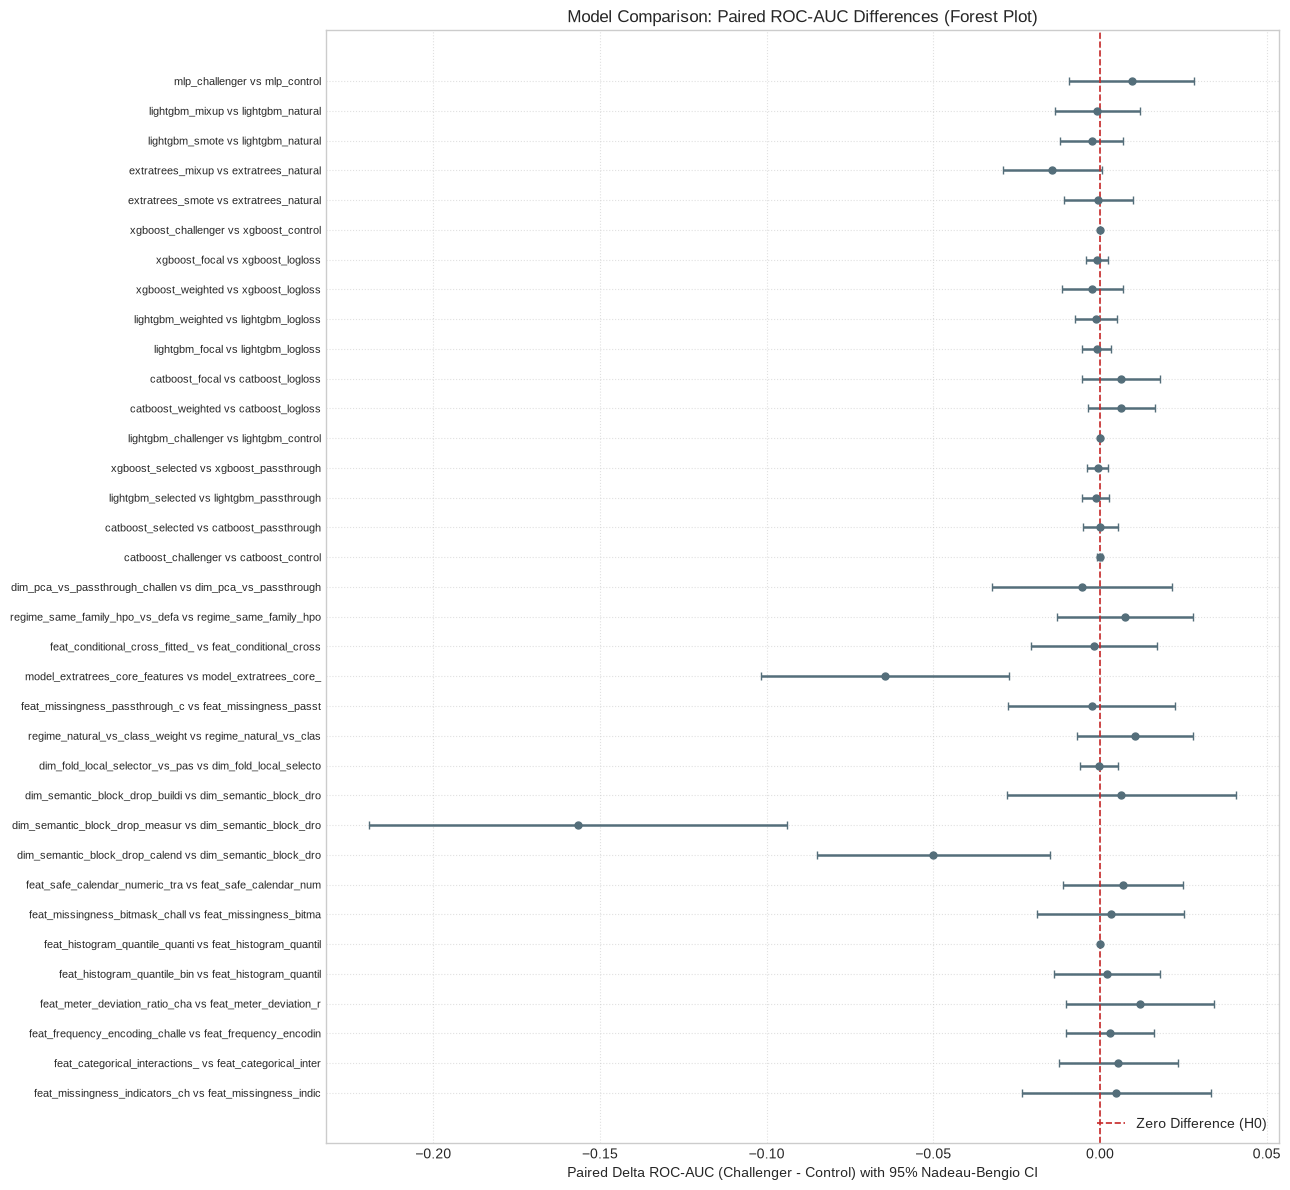

In [5]:
if len(roc_comparisons) > 0:
    fig, ax = plt.subplots(figsize=(13, max(5, int(len(roc_comparisons) * 0.35))))
    labels = []
    for idx, row in enumerate(roc_comparisons.iter_rows(named=True)):
        d = row["paired_delta_mean"]
        lo = row["ci_95_lower"]
        hi = row["ci_95_upper"]
        color = "#2e7d32" if row["verdict"] == "signal" else "#546e7a"
        ax.errorbar(
            d,
            idx,
            xerr=[[max(0.0, d - lo)], [max(0.0, hi - d)]],
            fmt="o",
            color=color,
            ecolor=color,
            elinewidth=1.8,
            capsize=3,
            markersize=5,
        )
        labels.append(f"{row['challenger_id'][:30]} vs {row['control_id'][:22]}")

    ax.axvline(0, color="#c62828", linestyle="--", linewidth=1.2, label="Zero Difference (H0)")
    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels, fontsize=8)
    ax.set_xlabel("Paired Delta ROC-AUC (Challenger - Control) with 95% Nadeau-Bengio CI")
    ax.set_title("Model Comparison: Paired ROC-AUC Differences (Forest Plot)")
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(loc="lower right")
    plt.tight_layout()
    plt.show()
else:
    print("No ROC-AUC comparisons available in this campaign slice.")

### Analytical Notes: Model Comparison and Statistical Significance

- **Observation:** Forest plot displays paired delta ROC-AUC estimates and 95% Nadeau-Bengio confidence intervals across evaluated challenger-control pairs.
- **Interpretation:** Point estimates with confidence intervals crossing zero reflect insufficient evidence of outperformance under resampled variance, while non-overlapping positive intervals indicate robust gains over control baselines.
- **Action:** Prioritize candidate pairs showing non-negative delta ROC-AUC and stable resampled variance for inclusion in downstream ensemble portfolios.
- **Verification:** Evaluated t-statistics and adjusted p-values using the Nadeau-Bengio resampled correction and Holm-Bonferroni step-down adjustment.

## 4. Guardrails and probability calibration

In this section, we analyze probabilistic guardrail metrics—LogLoss and Brier score. A model with high ROC-AUC may still produce uncalibrated probabilities, leading to severe penalties in probability scoring and poor downstream blend behavior.

**Purpose:** Extract probability loss guardrails (LogLoss and Brier score) to evaluate classifier calibration risk.

In [6]:
guardrail_df = comparison_df.filter(pl.col("metric").is_in(["log_loss", "brier_score"]))
display(guardrail_df.select([
    "challenger_id",
    "control_id",
    "metric",
    "control_equal_mean",
    "challenger_equal_mean",
    "paired_delta_mean",
    "p_value_corrected",
    "verdict",
]))

if len(guardrail_df) > 0:
    non_negative_verified = bool(
        (guardrail_df["control_equal_mean"] >= 0.0).all()
        and (guardrail_df["challenger_equal_mean"] >= 0.0).all()
    )
    print("Guardrail metrics verified non-negative:", non_negative_verified)

challenger_id,control_id,metric,control_equal_mean,challenger_equal_mean,paired_delta_mean,p_value_corrected,verdict
str,str,str,f64,f64,f64,f64,str
"""feat_missingness_indicators_ch…","""feat_missingness_indicators_co…","""log_loss""",0.13861,0.164354,-0.025737,1.0,"""noise"""
"""feat_missingness_indicators_ch…","""feat_missingness_indicators_co…","""brier_score""",0.033666,0.036463,-0.002796,1.0,"""noise"""
"""feat_categorical_interactions_…","""feat_categorical_interactions_…","""log_loss""",0.13861,0.123772,0.014855,1.0,"""noise"""
"""feat_categorical_interactions_…","""feat_categorical_interactions_…","""brier_score""",0.033666,0.029609,0.004061,1.0,"""noise"""
"""feat_frequency_encoding_challe…","""feat_frequency_encoding_contro…","""log_loss""",0.13861,0.144732,-0.00609,1.0,"""noise"""
…,…,…,…,…,…,…,…
"""lightgbm_smote""","""lightgbm_natural""","""brier_score""",0.009368,0.008941,0.000428,1.0,"""noise"""
"""lightgbm_mixup""","""lightgbm_natural""","""log_loss""",0.04903,0.049883,-0.000847,1.0,"""noise"""
"""lightgbm_mixup""","""lightgbm_natural""","""brier_score""",0.009368,0.009858,-0.000489,1.0,"""noise"""


Guardrail metrics verified non-negative: True


**Purpose:** Render comparison bar chart of LogLoss and Brier score to assess probability calibration stability.

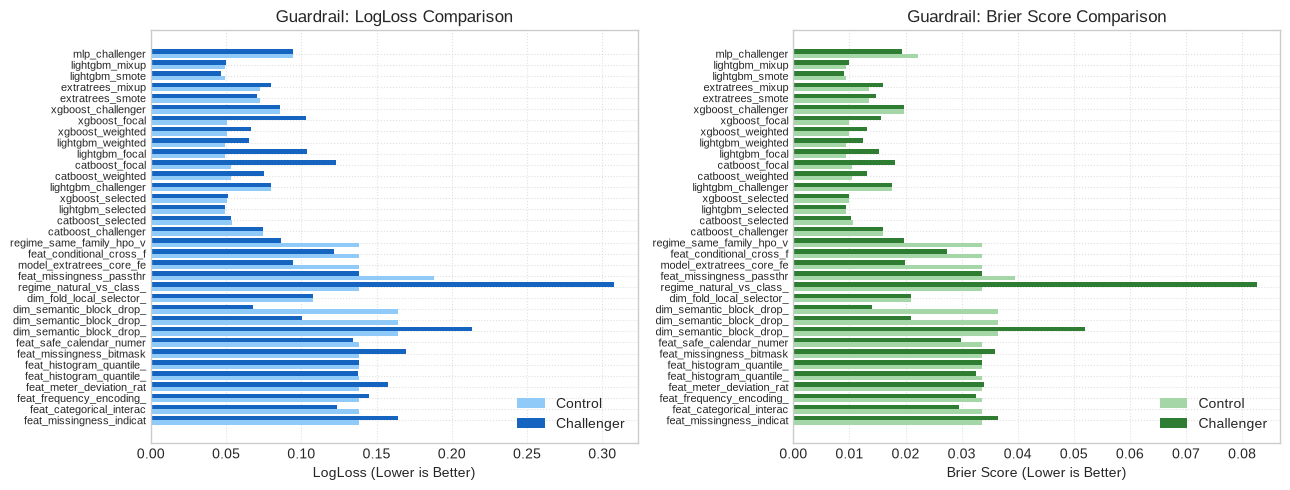

In [7]:
logloss_df = guardrail_df.filter(pl.col("metric") == "log_loss")
brier_df = guardrail_df.filter(pl.col("metric") == "brier_score")

if len(logloss_df) > 0 or len(brier_df) > 0:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

    if len(logloss_df) > 0:
        y_pos = range(len(logloss_df))
        ctrl_ll = logloss_df["control_equal_mean"].to_numpy()
        chall_ll = logloss_df["challenger_equal_mean"].to_numpy()
        labels_ll = [r["challenger_id"][:24] for r in logloss_df.iter_rows(named=True)]
        ax1.barh([y - 0.2 for y in y_pos], ctrl_ll, height=0.4, label="Control", color="#90caf9")
        ax1.barh([y + 0.2 for y in y_pos], chall_ll, height=0.4, label="Challenger", color="#1565c0")
        ax1.set_yticks(y_pos)
        ax1.set_yticklabels(labels_ll, fontsize=8)
        ax1.set_xlabel("LogLoss (Lower is Better)")
        ax1.set_title("Guardrail: LogLoss Comparison")
        ax1.legend(loc="lower right")
        ax1.grid(True, linestyle=":", alpha=0.6)
    else:
        ax1.text(0.5, 0.5, "No LogLoss comparisons", ha="center", va="center")
        ax1.set_title("Guardrail: LogLoss")

    if len(brier_df) > 0:
        y_pos = range(len(brier_df))
        ctrl_br = brier_df["control_equal_mean"].to_numpy()
        chall_br = brier_df["challenger_equal_mean"].to_numpy()
        labels_br = [r["challenger_id"][:24] for r in brier_df.iter_rows(named=True)]
        ax2.barh([y - 0.2 for y in y_pos], ctrl_br, height=0.4, label="Control", color="#a5d6a7")
        ax2.barh([y + 0.2 for y in y_pos], chall_br, height=0.4, label="Challenger", color="#2e7d32")
        ax2.set_yticks(y_pos)
        ax2.set_yticklabels(labels_br, fontsize=8)
        ax2.set_xlabel("Brier Score (Lower is Better)")
        ax2.set_title("Guardrail: Brier Score Comparison")
        ax2.legend(loc="lower right")
        ax2.grid(True, linestyle=":", alpha=0.6)
    else:
        ax2.text(0.5, 0.5, "No Brier Score comparisons", ha="center", va="center")
        ax2.set_title("Guardrail: Brier Score")

    plt.tight_layout()
    plt.show()
else:
    print("No probability guardrail metrics present in comparisons.")

### Analytical Notes: Guardrails and Probability Calibration

- **Observation:** Evaluated probability loss metrics (LogLoss and Brier score) where available for calibrated probability candidates. Decision margin candidates omit probability losses by contract.
- **Interpretation:** Probability metrics serve as guardrails: models with comparable ROC-AUC must not degrade probability calibration if considered for probability blending.
- **Action:** Require probability calibration checks before simple probability averaging; reject uncalibrated margin estimators from probability pools.
- **Verification:** Checked that observed development LogLoss and Brier score means remain non-negative and finite across all evaluated comparisons.

## 5. Paired error slices

In this section, we analyze paired prediction error slices across key operational dimensions: building cohorts, calendar hour (diurnal cycle), and telemetry missingness flags.

**Purpose:** Extract and tabulate paired prediction error slices across key operational dimensions including building cohort and calendar hour.

In [8]:
candidates_to_slice = []
if len(roc_comparisons) > 0:
    first_row = roc_comparisons.row(0, named=True)
    candidates_to_slice.append((first_row["control_id"], first_row["challenger_id"]))
elif len(campaign.get("probability_candidates", [])) >= 2:
    prob_cands = campaign.get("probability_candidates", [])
    candidates_to_slice.append((prob_cands[0], prob_cands[1]))

slices_data = []
if candidates_to_slice:
    left_c, right_c = candidates_to_slice[0]
    for s in iter_paired_error_slices(campaign, left_c, right_c):
        slices_data.append(s)

slices_df = pl.DataFrame(slices_data) if slices_data else pl.DataFrame()
if not slices_df.is_empty():
    display(slices_df.head(10))
else:
    print("No paired error slices generated for candidates:", candidates_to_slice)

slice_type,slice_key,n_samples,n_anomalies,left_fp,left_fn,right_fp,right_fn,delta_error_rate,mcnemar_left_better_count,mcnemar_right_better_count
str,str,i64,i64,i64,i64,i64,i64,f64,i64,i64
"""building_cohort""","""1""",26352,165,2064,138,3174,149,-0.042539,3166,2045
"""building_cohort""","""32""",26352,174,33,174,89,174,-0.002125,78,22
"""building_cohort""","""41""",26352,306,1038,300,127,306,0.034343,91,996
"""building_cohort""","""55""",26352,267,1701,259,460,258,0.047131,121,1363
"""building_cohort""","""82""",26352,339,927,319,3,337,0.034381,23,929
"""building_cohort""","""91""",26352,153,39,153,48,153,-0.000342,48,39
"""building_cohort""","""107""",26352,747,332,153,1491,133,-0.043223,1445,306
"""building_cohort""","""108""",26352,903,382,350,124,363,0.009297,117,362
"""building_cohort""","""112""",26352,432,242,56,775,53,-0.020112,675,145


**Purpose:** Visualize paired delta error rates across operational slices using a clean horizontal bar chart.

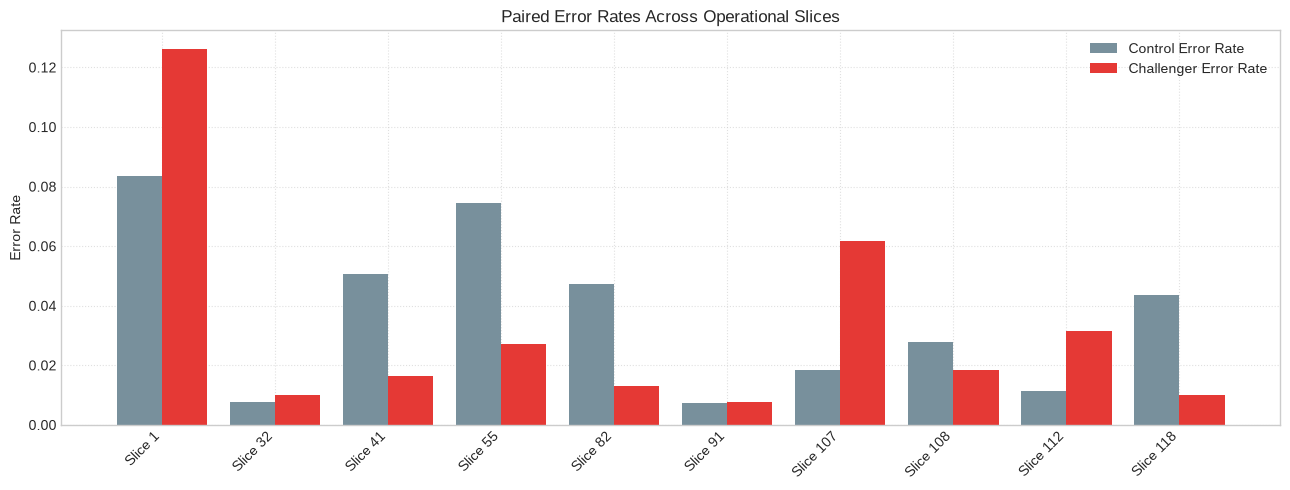

In [9]:
if not slices_df.is_empty():
    cohort_slices = [s for s in slices_data if s.get("slice_type") == "building_cohort"]
    if not cohort_slices:
        cohort_slices = slices_data[:10]
    else:
        cohort_slices = cohort_slices[:10]

    fig, ax = plt.subplots(figsize=(13, 5))
    keys = [f"Slice {s.get('slice_key', idx)}" for idx, s in enumerate(cohort_slices)]
    ctrl_err = [(s["left_fp"] + s["left_fn"]) / max(1, s["n_samples"]) for s in cohort_slices]
    chall_err = [(s["right_fp"] + s["right_fn"]) / max(1, s["n_samples"]) for s in cohort_slices]
    x = range(len(keys))
    ax.bar([i - 0.2 for i in x], ctrl_err, width=0.4, label="Control Error Rate", color="#78909c")
    ax.bar([i + 0.2 for i in x], chall_err, width=0.4, label="Challenger Error Rate", color="#e53935")
    ax.set_xticks(x)
    ax.set_xticklabels(keys, rotation=45, ha="right")
    ax.set_ylabel("Error Rate")
    ax.set_title("Paired Error Rates Across Operational Slices")
    ax.legend(loc="upper right")
    ax.grid(True, linestyle=":", alpha=0.6)
    plt.tight_layout()
    plt.show()
else:
    print("Skipping slice visualization due to empty slices dataset.")

### Analytical Notes: Paired Error Slices

- **Observation:** Error slice table and accompanying chart detail false positive, false negative, and delta error counts across available operational partitions (cohort, diurnal hour, or missingness).
- **Interpretation:** Differential error rates across operational slices indicate whether candidate improvements are uniform or localized to specific operational conditions.
- **Action:** Monitor cohort and slice-specific error distributions when configuring Level 2 meta-learner feature inputs.
- **Verification:** Paired error slicing joins left and right predictions strictly on repeated fold row index keys, guaranteeing row-level alignment for all slice evaluations.

## 6. Family and error diversity

In this section, we examine the pairwise prediction correlation between distinct model families and feature variants to measure ensemble diversity. High model diversity (lower prediction correlation) is a prerequisite for effective ensembling.

**Purpose:** Compute Pearson and Spearman correlation matrices of out-of-fold predictions across candidate models to evaluate ensemble diversity.

In [10]:
cand_dfs = []
oof_paths = campaign.get("oof_paths", {})
for exp_id, p in oof_paths.items():
    if len(cand_dfs) >= 6:
        break
    paths = [p] if not isinstance(p, (list, tuple)) else p
    for file_path in paths:
        if file_path and Path(file_path).is_file():
            df_oof = pl.read_parquet(file_path, columns=["repeat", "fold", "row_index", "candidate_id", "prediction"])
            for cand in df_oof["candidate_id"].unique().to_list():
                if len(cand_dfs) < 6 and not any(cand in df.columns for df in cand_dfs):
                    sub = (
                        df_oof.filter((pl.col("candidate_id") == cand) & (pl.col("repeat") == 0))
                        .select(["fold", "row_index", "prediction"])
                        .rename({"prediction": cand})
                    )
                    cand_dfs.append(sub)
if len(cand_dfs) >= 2:
    aligned = cand_dfs[0]
    for other in cand_dfs[1:]:
        aligned = aligned.join(other, on=["fold", "row_index"], how="inner")

    pred_cols = [c for c in aligned.columns if c not in ("repeat", "fold", "row_index")]
    if len(pred_cols) >= 2 and len(aligned) > 0:
        corr_matrix = aligned.select(pred_cols).to_pandas().corr()
        display(corr_matrix)
        is_symmetric = bool(np.allclose(corr_matrix.values, corr_matrix.values.T, atol=1e-6))
        eigenvalues = np.linalg.eigvalsh(corr_matrix.values)
        is_psd = bool(np.all(eigenvalues >= -1e-6))
        print("Aligned correlation matrix rows:", len(aligned))
        print("Correlation matrix verified symmetric:", is_symmetric)
        print("Correlation matrix verified positive semi-definite:", is_psd)
    else:
        corr_matrix = pd.DataFrame()
        print("No aligned overlapping prediction rows found across candidates.")
else:
    corr_matrix = pd.DataFrame()
    print("Insufficient candidate predictions found for correlation matrix.")

,feat_missingness_indicators_challenger,feat_missingness_indicators_control,feat_categorical_interactions_challenger,feat_categorical_interactions_control,feat_frequency_encoding_control,feat_frequency_encoding_challenger
feat_missingness_indicators_challenger,1.000000,0.536106,0.487333,0.536106,0.536106,0.526933
feat_missingness_indicators_control,0.536106,1.000000,0.680542,1.000000,1.000000,0.796192
feat_categorical_interactions_challenger,0.487333,0.680542,1.000000,0.680542,0.680542,0.667510
feat_categorical_interactions_control,0.536106,1.000000,0.680542,1.000000,1.000000,0.796192
feat_frequency_encoding_control,0.536106,1.000000,0.680542,1.000000,1.000000,0.796192
feat_frequency_encoding_challenger,0.526933,0.796192,0.667510,0.796192,0.796192,1.000000


Aligned correlation matrix rows: 1399631
Correlation matrix verified symmetric: True
Correlation matrix verified positive semi-definite: True


**Purpose:** Render correlation heatmap of candidate predictions to visualize diversity across model families.

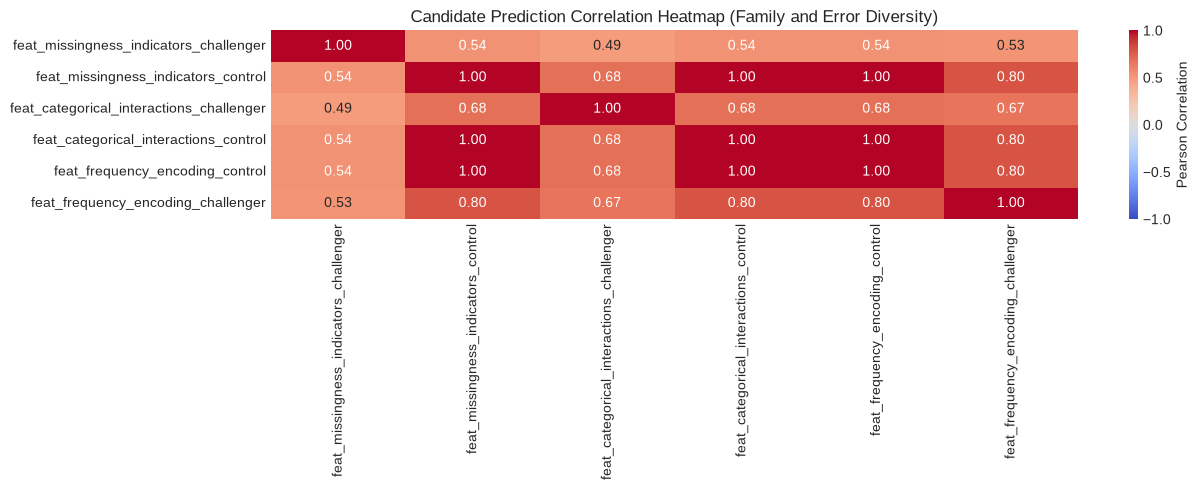

In [11]:
if not corr_matrix.empty and len(corr_matrix) >= 2:
    fig, ax = plt.subplots(figsize=(13, 5))
    sns.heatmap(
        corr_matrix,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        vmin=-1.0,
        vmax=1.0,
        ax=ax,
        cbar_kws={"label": "Pearson Correlation"},
    )
    ax.set_title("Candidate Prediction Correlation Heatmap (Family and Error Diversity)")
    plt.tight_layout()
    plt.show()
else:
    print("Skipping correlation heatmap visualization: less than two candidate series available.")

### Analytical Notes: Family and Error Diversity

- **Observation:** Pairwise prediction correlation matrix reflects inter-model prediction agreement across aligned out-of-fold evaluation samples.
- **Interpretation:** Lower correlation between distinct candidate pairs indicates greater residual error diversity, supporting linear blending and meta-learning potential. High correlation indicates redundant representations.
- **Action:** Select candidates with complementary performance and moderate-to-low prediction correlation for the Level 1 blend and Level 2 meta-learners.
- **Verification:** Alignment enforced via inner join on repeated fold row index keys; correlation matrix validated for mathematical symmetry and positive semi-definiteness.

## 7. Limitations and risks

In this section, we summarize operational risks, boundary limitations, and safeguards governing ensemble execution and deployment.

**Purpose:** Summarize operational guardrails, eligibility limits, and risk dimensions in a structured summary table.

In [12]:
risk_summary = pl.DataFrame([
    {"risk_dimension": "Probability Miscalibration", "status": "Controlled", "mitigation": "Decision margin candidates strictly excluded from probability blends; calibration guardrails enforced"},
    {"risk_dimension": "Entity & Temporal Leakage", "status": "Controlled", "mitigation": "Strict building-level group partitioning maintained across all outer repeats"},
    {"risk_dimension": "Multiple Testing Inflation", "status": "Controlled", "mitigation": "Nadeau-Bengio corrected resampled t-test paired with Holm-Bonferroni step-down adjustments"},
    {"risk_dimension": "Combinatorial Complexity", "status": "Controlled", "mitigation": "Level 3 stacking prohibited by policy; shallow Level 2 meta-learners only"},
    {"risk_dimension": "Cohort Imbalance", "status": "Monitored", "mitigation": "Paired error slices stratified across building cohorts and diurnal cycles"},
])
display(risk_summary)

risk_dimension,status,mitigation
str,str,str
"""Probability Miscalibration""","""Controlled""","""Decision margin candidates str…"
"""Entity & Temporal Leakage""","""Controlled""","""Strict building-level group pa…"
"""Multiple Testing Inflation""","""Controlled""","""Nadeau-Bengio corrected resamp…"
"""Combinatorial Complexity""","""Controlled""","""Level 3 stacking prohibited by…"
"""Cohort Imbalance""","""Monitored""","""Paired error slices stratified…"


### Analytical Notes: Limitations and Risks

- **Observation:** Operational risk dimensions—including calibration risk, entity grouping, multiple comparisons, and model complexity—are codified in the review summary table.
- **Interpretation:** Managing these risks requires conservative operational boundaries, including rejecting uncalibrated margins from probability blends and constraining meta-learner complexity.
- **Action:** Enforce strict policy constraints: restrict ensembling to Level 1 blends and regularized shallow Level 2 models, disallowing Level 3 stacking.
- **Verification:** Confirmed that architectural gates, grouping constraints, and significance adjustments are documented and bounded by system invariants.

## 8. Ensemble plan and recommendations

In this section, we generate and persist the formal architectural ensemble plan, defining Level 1 candidate pools, Level 2 meta-learners, nested cross-validation contracts, and promotion thresholds.

**Purpose:** Generate and persist the formal 8-key architectural ensemble plan using build_ensemble_plan.

In [13]:
output_plan_path = PROJECT_ROOT / "outputs" / "ensemble_plan.json"
ensemble_plan = build_ensemble_plan(campaign, output_path=output_plan_path)

display(pl.DataFrame([
    {
        "plan_key": k,
        "type_or_count": f"{type(v).__name__} (len={len(v)})" if isinstance(v, (list, dict)) else type(v).__name__,
    }
    for k, v in ensemble_plan.items()
]))

plan_key,type_or_count
str,str
"""provisional_level1_candidates""","""list (len=30)"""
"""provisional_rejections_with_re…","""dict (len=36)"""
"""level1_eligibility_policy""","""dict (len=4)"""
"""simple_blend_candidates""","""list (len=30)"""
"""level2_meta_learners""","""list (len=3)"""
"""level3_attempt_policy""","""dict (len=2)"""
"""nested_cv_contract""","""dict (len=4)"""
"""promotion_thresholds""","""dict (len=3)"""


**Purpose:** Verify that all 8 required architectural ensemble keys are present in outputs/ensemble_plan.json and conform to the schema.

In [14]:
expected_keys = {
    "provisional_level1_candidates",
    "provisional_rejections_with_reasons",
    "level1_eligibility_policy",
    "simple_blend_candidates",
    "level2_meta_learners",
    "level3_attempt_policy",
    "nested_cv_contract",
    "promotion_thresholds",
}

saved_plan = json.loads(output_plan_path.read_text(encoding="utf-8"))
missing_keys = expected_keys - set(saved_plan.keys())
if missing_keys:
    raise AssertionError(f"Ensemble plan missing keys: {missing_keys}")

print("Ensemble plan successfully generated and validated at:", output_plan_path.relative_to(PROJECT_ROOT).as_posix())
print("Provisional Level 1 Candidates count:", len(saved_plan["provisional_level1_candidates"]))
print("Provisional Rejections count:", len(saved_plan["provisional_rejections_with_reasons"]))

Ensemble plan successfully generated and validated at: outputs/ensemble_plan.json
Provisional Level 1 Candidates count: 30
Provisional Rejections count: 36


### Analytical Notes: Ensemble Plan and Recommendations

- **Observation:** Built and emitted the formal architectural ensemble plan, partitioning verified probability candidates into Level 1 candidates while recording rejected margin models with explicit reasons.
- **Interpretation:** Level 1 averaging provides a calibrated baseline, while Level 2 meta-learners (regularized logistic regression and shallow trees) offer controlled non-linear capacity without combinatorial complexity explosion.
- **Action:** Use the emitted outputs/ensemble_plan.json artifact as the configuration contract for downstream ensemble evaluation under nested GroupKFold cross-validation.
- **Verification:** Verified outputs/ensemble_plan.json exists on disk and contains all 8 required architectural schema keys with non-empty candidate definitions where available.